### Read and import

In [1]:
# import necessary lib
import pandas as pd
import numpy as np
import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

In [2]:
events = duckdb.sql('SELECT * FROM "../dataset/raw/events.csv";')
inventory_items = duckdb.sql('SELECT * FROM "../dataset/raw/inventory_items.csv";')
orders =duckdb.sql("SELECT * FROM read_csv('../dataset/raw/orders.csv', types={'gender': 'VARCHAR'})")
order_items = duckdb.sql('SELECT * FROM "../dataset/raw/order_items.csv"')
users = duckdb.sql('SELECT * FROM "../dataset/raw/users.csv"')

### 1. Data Checking

#### 1. **events**
- user_id(null value) indicate Guest/Anonymous Users, change to **0**
- city('null') change to **'unknown'**

In [3]:
duckdb.sql('SELECT * FROM events')

┌─────────┬─────────┬─────────────────┬──────────────────────────────────────┬─────────────────────┬─────────────────┬────────────────────┬───────────┬─────────────┬─────────┬────────────────┬─────────────────────────────────────────────────────────────────┬────────────┐
│   id    │ user_id │ sequence_number │              session_id              │     created_at      │   ip_address    │        city        │   state   │ postal_code │ browser │ traffic_source │                               uri                               │ event_type │
│  int64  │  int64  │      int64      │               varchar                │      timestamp      │     varchar     │      varchar       │  varchar  │   varchar   │ varchar │    varchar     │                             varchar                             │  varchar   │
├─────────┼─────────┼─────────────────┼──────────────────────────────────────┼─────────────────────┼─────────────────┼────────────────────┼───────────┼─────────────┼─────────┼─────────

In [4]:
duckdb.sql('SELECT COUNT(*) FROM events WHERE user_id IS NULL ')

┌──────────────┐
│ count_star() │
│    int64     │
├──────────────┤
│      1125645 │
└──────────────┘

In [5]:
t = duckdb.sql('SELECT * FROM events WHERE user_id IS NULL ORDER BY session_id,sequence_number ,created_at ASC')
duckdb.sql('SELECT * FROM users AS u INNER JOIN t ON u.id=t.user_id')

┌───────┬────────────┬───────────┬─────────┬───────┬─────────┬─────────┬────────────────┬─────────────┬─────────┬─────────┬──────────┬───────────┬────────────────┬────────────┬───────────┬───────┬─────────┬─────────────────┬────────────┬──────────────┬────────────┬─────────┬─────────┬───────────────┬─────────┬──────────────────┬─────────┬────────────┐
│  id   │ first_name │ last_name │  email  │  age  │ gender  │  state  │ street_address │ postal_code │  city   │ country │ latitude │ longitude │ traffic_source │ created_at │ user_geom │ id_1  │ user_id │ sequence_number │ session_id │ created_at_1 │ ip_address │ city_1  │ state_1 │ postal_code_1 │ browser │ traffic_source_1 │   uri   │ event_type │
│ int64 │  varchar   │  varchar  │ varchar │ int64 │ varchar │ varchar │    varchar     │   varchar   │ varchar │ varchar │  double  │  double   │    varchar     │ timestamp  │  varchar  │ int64 │  int64  │      int64      │  varchar   │  timestamp   │  varchar   │ varchar │ varchar │    var

In [6]:
duckdb.sql("SELECT * FROM events WHERE city = 'null'")

┌─────────┬─────────┬─────────────────┬──────────────────────────────────────┬─────────────────────┬─────────────────┬─────────┬─────────────────────┬─────────────┬─────────┬────────────────┬────────────────────────────────────────────────────────────────┬────────────┐
│   id    │ user_id │ sequence_number │              session_id              │     created_at      │   ip_address    │  city   │        state        │ postal_code │ browser │ traffic_source │                              uri                               │ event_type │
│  int64  │  int64  │      int64      │               varchar                │      timestamp      │     varchar     │ varchar │       varchar       │   varchar   │ varchar │    varchar     │                            varchar                             │  varchar   │
├─────────┼─────────┼─────────────────┼──────────────────────────────────────┼─────────────────────┼─────────────────┼─────────┼─────────────────────┼─────────────┼─────────┼────────────────

#### 2. **inventory_items**
- null product_brand,product_name change to **'unknown'**

In [7]:
inventory_items.describe()

┌─────────┬────────────────────┬────────────────────┬────────────────────────────┬────────────────────────────┬────────────────────┬──────────────────┬──────────────────────────────────────────────────────────────┬───────────────┬──────────────────────┬────────────────────┬──────────────────────────────────┬────────────────────────────────┐
│  aggr   │         id         │     product_id     │         created_at         │          sold_at           │        cost        │ product_category │                         product_name                         │ product_brand │ product_retail_price │ product_department │           product_sku            │ product_distribution_center_id │
│ varchar │       double       │       double       │          varchar           │          varchar           │       double       │     varchar      │                           varchar                            │    varchar    │        double        │      varchar       │             varchar              │     

In [8]:
duckdb.sql("""
SELECT
    *
FROM
    inventory_items
WHERE
    product_name IS NULL
""")

┌────────┬────────────┬─────────────────────┬─────────────────────┬────────────────────┬───────────────────┬──────────────┬─────────────────┬──────────────────────┬────────────────────┬──────────────────────────────────┬────────────────────────────────┐
│   id   │ product_id │     created_at      │       sold_at       │        cost        │ product_category  │ product_name │  product_brand  │ product_retail_price │ product_department │           product_sku            │ product_distribution_center_id │
│ int64  │   int64    │      timestamp      │      timestamp      │       double       │      varchar      │   varchar    │     varchar     │        double        │      varchar       │             varchar              │             int64              │
├────────┼────────────┼─────────────────────┼─────────────────────┼────────────────────┼───────────────────┼──────────────┼─────────────────┼──────────────────────┼────────────────────┼──────────────────────────────────┼──────────────────

#### 3. **orders**
- returned_at, shipped_at, delivered_at(null values) **keep**
- created_at, shipped_at, delivered_at, returned_at Dtype change to **timestamp**

In [9]:
orders

┌──────────┬─────────┬───────────┬─────────┬─────────────────────┬─────────────┬─────────────────────┬─────────────────────┬─────────────┐
│ order_id │ user_id │  status   │ gender  │     created_at      │ returned_at │     shipped_at      │    delivered_at     │ num_of_item │
│  int64   │  int64  │  varchar  │ varchar │      timestamp      │   varchar   │      timestamp      │      timestamp      │    int64    │
├──────────┼─────────┼───────────┼─────────┼─────────────────────┼─────────────┼─────────────────────┼─────────────────────┼─────────────┤
│       29 │      28 │ Cancelled │ F       │ 2025-04-08 16:22:30 │ NULL        │ NULL                │ NULL                │           1 │
│       30 │      28 │ Cancelled │ F       │ 2026-05-14 10:50:42 │ NULL        │ NULL                │ NULL                │           1 │
│       38 │      31 │ Cancelled │ F       │ 2024-11-11 15:24:28 │ NULL        │ NULL                │ NULL                │           1 │
│       69 │      55 │ Canc

In [10]:
duckdb.sql("SELECT * FROM orders WHERE shipped_at IS NULL AND delivered_at IS NOT NULL AND returned_at IS NOT NULL")

┌──────────┬─────────┬─────────┬─────────┬────────────┬─────────────┬────────────┬──────────────┬─────────────┐
│ order_id │ user_id │ status  │ gender  │ created_at │ returned_at │ shipped_at │ delivered_at │ num_of_item │
│  int64   │  int64  │ varchar │ varchar │ timestamp  │   varchar   │ timestamp  │  timestamp   │    int64    │
└──────────┴─────────┴─────────┴─────────┴────────────┴─────────────┴────────────┴──────────────┴─────────────┘
                                                    0 rows                                                   

#### 4. **order_items**
- created_at, shipped_at, delivered_at, returned_at Dtype change to **timestamp**

In [11]:
order_items

┌────────┬──────────┬─────────┬────────────┬───────────────────┬────────────┬─────────────────────┬─────────────────────┬─────────────────────┬─────────────────────┬────────────────────┐
│   id   │ order_id │ user_id │ product_id │ inventory_item_id │   status   │     created_at      │     shipped_at      │    delivered_at     │     returned_at     │     sale_price     │
│ int64  │  int64   │  int64  │   int64    │       int64       │  varchar   │      timestamp      │      timestamp      │      timestamp      │      timestamp      │       double       │
├────────┼──────────┼─────────┼────────────┼───────────────────┼────────────┼─────────────────────┼─────────────────────┼─────────────────────┼─────────────────────┼────────────────────┤
│ 123726 │    85157 │   68281 │      14235 │            333975 │ Complete   │ 2026-09-28 10:50:40 │ 2026-09-29 06:48:47 │ 2026-10-01 04:11:47 │ NULL                │ 0.0199999995529651 │
│ 150932 │   103936 │   83088 │      14235 │            407383 │ 

In [12]:
duckdb.sql("SELECT * FROM order_items WHERE id IS NULL OR order_id IS NULL OR user_id IS NULL OR product_id IS NULL OR inventory_item_id  IS NULL")

┌───────┬──────────┬─────────┬────────────┬───────────────────┬─────────┬────────────┬────────────┬──────────────┬─────────────┬────────────┐
│  id   │ order_id │ user_id │ product_id │ inventory_item_id │ status  │ created_at │ shipped_at │ delivered_at │ returned_at │ sale_price │
│ int64 │  int64   │  int64  │   int64    │       int64       │ varchar │ timestamp  │ timestamp  │  timestamp   │  timestamp  │   double   │
└───────┴──────────┴─────────┴────────────┴───────────────────┴─────────┴────────────┴────────────┴──────────────┴─────────────┴────────────┘
                                                                   0 rows                                                                  

In [13]:
duckdb.sql("SELECT status,COUNT(status) FROM order_items GROUP BY status")

┌────────────┬───────────────┐
│   status   │ count(status) │
│  varchar   │     int64     │
├────────────┼───────────────┤
│ Complete   │         45430 │
│ Returned   │         18337 │
│ Cancelled  │         26967 │
│ Processing │         36469 │
│ Shipped    │         54263 │
└────────────┴───────────────┘

#### 5. **users**

In [14]:
users

┌───────┬─────────────┬───────────┬─────────────────────────────────┬───────┬─────────┬─────────┬──────────────────────────────────┬─────────────┬─────────┬─────────────┬──────────────┬──────────────┬────────────────┬────────────────────────────┬──────────────────────────────────┐
│  id   │ first_name  │ last_name │              email              │  age  │ gender  │  state  │          street_address          │ postal_code │  city   │   country   │   latitude   │  longitude   │ traffic_source │         created_at         │            user_geom             │
│ int64 │   varchar   │  varchar  │             varchar             │ int64 │ varchar │ varchar │             varchar              │   varchar   │ varchar │   varchar   │    double    │    double    │    varchar     │         timestamp          │             varchar              │
├───────┼─────────────┼───────────┼─────────────────────────────────┼───────┼─────────┼─────────┼──────────────────────────────────┼─────────────┼────────

### 2. Data Cleaning + EDA

#### 2.1 events table

In [15]:
## 1.events
clean_events= duckdb.sql("""
SELECT
    id,
    COALESCE(user_id,0) AS user_id,
    sequence_number,
    session_id,
    created_at,
    ip_address,
    CASE WHEN
        city = 'null' THEN 'Unknown' ELSE
        city
    END AS city,
    state,
    postal_code,
    browser,
    traffic_source,
    uri,
    event_type
FROM events
""")

---
**EDA**

In [16]:
df= clean_events.df()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2428103 entries, 0 to 2428102
Data columns (total 13 columns):
 #   Column           Dtype         
---  ------           -----         
 0   id               int64         
 1   user_id          int64         
 2   sequence_number  int64         
 3   session_id       object        
 4   created_at       datetime64[us]
 5   ip_address       object        
 6   city             object        
 7   state            object        
 8   postal_code      object        
 9   browser          object        
 10  traffic_source   object        
 11  uri              object        
 12  event_type       object        
dtypes: datetime64[us](1), int64(3), object(9)
memory usage: 240.8+ MB


In [17]:
df.describe()

,id,user_id,sequence_number,created_at
count,2.428103e+06,2.428103e+06,2.428103e+06,2428103
mean,1.214052e+06,2.684218e+04,3.308997e+00,2023-12-15 17:19:35.396426
min,1.000000e+00,0.000000e+00,1.000000e+00,2019-01-02 00:09:00
25%,6.070265e+05,0.000000e+00,1.000000e+00,2022-04-09 04:40:00
50%,1.214052e+06,6.852000e+03,2.000000e+00,2024-06-06 23:12:15
75%,1.821078e+06,5.340900e+04,4.000000e+00,2025-12-01 11:20:34
max,2.428103e+06,1.000000e+05,1.300000e+01,2026-10-12 23:55:20.723856
std,7.009331e+05,3.265723e+04,2.667489e+00,NaN


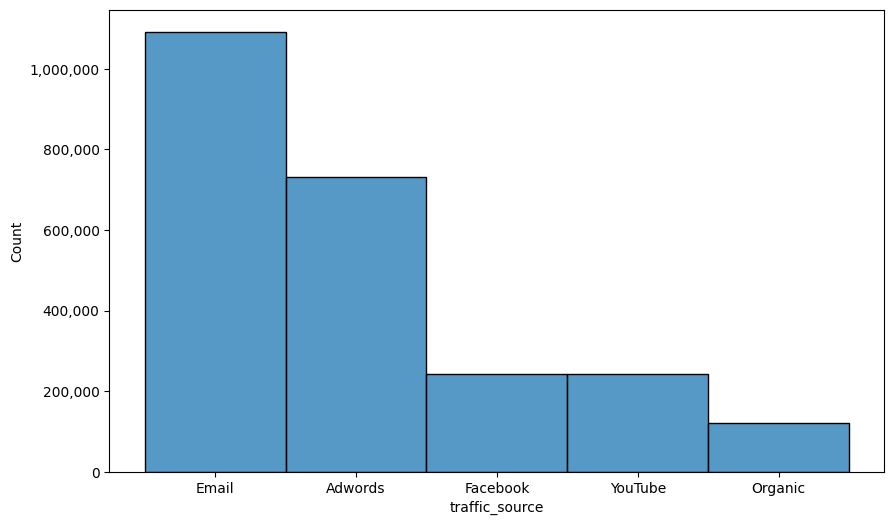

In [18]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='traffic_source')
plt.gca().yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
plt.show()

In [82]:
clean_events.to_parquet('../dataset/processed/clean_events.parquet')

#### 2.2 inventory_items table

In [19]:
# 2.inventory_items
clean_inventory_items=duckdb.sql("""
SELECT
    id,
    product_id,
    created_at,
    sold_at,
    cost,
    product_category,
    COALESCE(product_name,'Unknown') AS product_name,
    COALESCE(product_brand,'Unknown') AS product_brand,
    product_retail_price,
    product_department,
    product_sku,
    product_distribution_center_id
FROM
    inventory_items
""")

---
**EDA**

In [20]:
df =clean_inventory_items.df()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 491228 entries, 0 to 491227
Data columns (total 12 columns):
 #   Column                          Non-Null Count   Dtype         
---  ------                          --------------   -----         
 0   id                              491228 non-null  int64         
 1   product_id                      491228 non-null  int64         
 2   created_at                      491228 non-null  datetime64[us]
 3   sold_at                         181946 non-null  datetime64[us]
 4   cost                            491228 non-null  float64       
 5   product_category                491228 non-null  object        
 6   product_name                    491228 non-null  object        
 7   product_brand                   491228 non-null  object        
 8   product_retail_price            491228 non-null  float64       
 9   product_department              491228 non-null  object        
 10  product_sku                     491228 non-null  object 

In [21]:
df.describe()

,id,product_id,created_at,sold_at,cost,product_retail_price,product_distribution_center_id
count,491228.000000,491228.000000,491228,181946,491228.000000,491228.000000,491228.000000
mean,245614.500000,15300.980879,2023-12-01 04:29:34.879896,2024-11-20 16:24:22.717190,28.775064,59.819350,4.999389
min,1.000000,1.000000,2018-12-01 15:41:57,2019-01-11 18:29:44,0.008300,0.020000,1.000000
25%,122807.750000,8025.000000,2022-04-09 04:19:20.750000,2023-11-10 23:06:49.250000,11.439120,24.950001,2.000000
50%,245614.500000,16065.500000,2024-03-07 10:21:19,2025-05-22 04:26:56,19.987000,39.990002,5.000000
75%,368421.250000,22568.000000,2025-09-15 11:23:57,2026-04-24 16:45:56.500000,34.748000,69.980003,8.000000
max,491228.000000,29120.000000,2026-10-14 11:42:00.037604,2026-10-15 00:13:51.216575,557.151002,999.000000,10.000000
std,141805.453354,8417.954620,NaN,NaN,30.871576,66.622865,2.898489


total 491228 item records, 181946 sold and remains 309282 at the store

In [22]:
df.query("created_at > sold_at or cost > product_retail_price")

,id,product_id,created_at,sold_at,cost,product_category,product_name,product_brand,product_retail_price,product_department,product_sku,product_distribution_center_id


In [23]:
print(df.columns.tolist())

['id', 'product_id', 'created_at', 'sold_at', 'cost', 'product_category', 'product_name', 'product_brand', 'product_retail_price', 'product_department', 'product_sku', 'product_distribution_center_id']


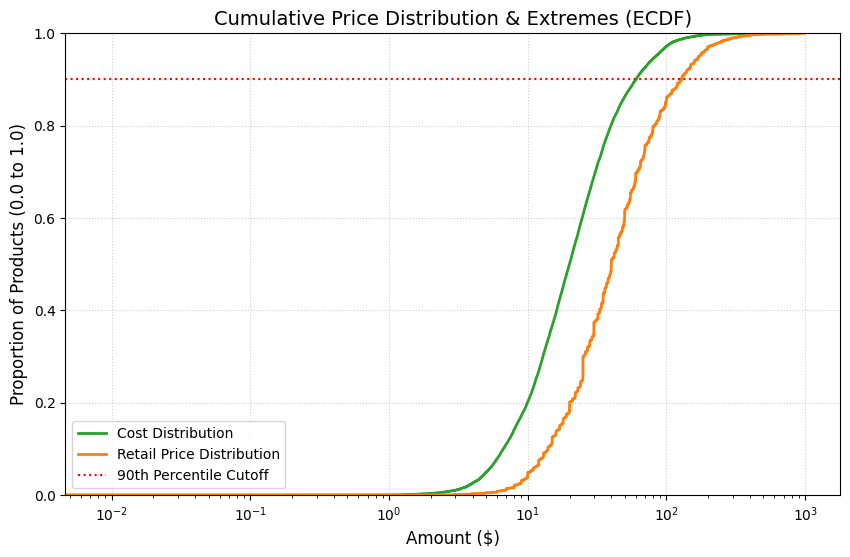

In [24]:
plt.figure(figsize=(10, 6))

sns.ecdfplot(data=df, x='cost', label='Cost Distribution', color='#2ca02c', linewidth=2)
sns.ecdfplot(data=df, x='product_retail_price', label='Retail Price Distribution', color='#ff7f0e', linewidth=2)
plt.axhline(y=0.90, color='red', linestyle=':', label='90th Percentile Cutoff')
plt.title('Cumulative Price Distribution & Extremes (ECDF)', fontsize=14)
plt.xlabel('Amount ($)', fontsize=12)
plt.ylabel('Proportion of Products (0.0 to 1.0)', fontsize=12)
plt.gca().xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.xscale('log')
plt.show()

In [ ]:
clean_inventory_items.to_parquet('../dataset/processed/clean_inventory_items.parquet')

#### 2.3 orders table

In [25]:
# 3. orders
clean_orders= duckdb.sql("""
SELECT
    order_id,
    user_id,
    status,
    gender,
    TRY_CAST(created_at AS timestamp) AS created_at,
    TRY_CAST(returned_at AS timestamp) AS returned_at,
    TRY_CAST(shipped_at AS timestamp) AS shipped_at,
    TRY_CAST(delivered_at AS timestamp) AS delivered_at,
    num_of_item
FROM
    orders
""")

---
**EDA**

In [26]:
df = clean_orders.df()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 124978 entries, 0 to 124977
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   order_id      124978 non-null  int64         
 1   user_id       124978 non-null  int64         
 2   status        124978 non-null  object        
 3   gender        124978 non-null  object        
 4   created_at    124978 non-null  datetime64[us]
 5   returned_at   12651 non-null   datetime64[us]
 6   shipped_at    81184 non-null   datetime64[us]
 7   delivered_at  43941 non-null   datetime64[us]
 8   num_of_item   124978 non-null  int64         
dtypes: datetime64[us](4), int64(3), object(2)
memory usage: 8.6+ MB


In [27]:
df.describe()

,order_id,user_id,created_at,returned_at,shipped_at,delivered_at,num_of_item
count,124978.000000,124978.000000,124978,12651,81184,43941,124978.000000
mean,62489.500000,50094.584863,2024-11-15 06:58:47.877269,2024-11-28 05:52:01.672567,2024-11-16 18:43:56.026773,2024-11-21 09:07:10.266143,1.451984
min,1.000000,2.000000,2019-01-05 20:04:52,2019-02-13 21:22:23,2019-01-08 02:43:52,2019-01-10 23:55:52,1.000000
25%,31245.250000,25180.500000,2023-11-02 20:07:01.250000,2023-11-23 15:19:00,2023-11-04 07:42:01,2023-11-09 16:29:12,1.000000
50%,62489.500000,50213.000000,2025-05-17 17:18:01.500000,2025-05-31 03:11:28,2025-05-19 19:31:31.500000,2025-05-27 13:25:34,1.000000
75%,93733.750000,75002.750000,2026-04-21 03:53:44.750000,2026-04-29 08:34:28,2026-04-21 18:05:44.500000,2026-04-25 11:49:11,2.000000
max,124978.000000,100000.000000,2026-10-09 00:34:14.224402,2026-10-18 16:32:27.983876,2026-10-11 22:37:53,2026-10-16 18:37:27.769125,4.000000
std,36078.185309,28812.572108,NaN,NaN,NaN,NaN,0.805468


In [28]:
return_rate = 100.0 * df['returned_at'].count() / df['created_at'].count()
print(f"This dataset consists of {df['order_id'].count()} records and the return rate is {return_rate:.3f}%")

This dataset consists of 124978 records and the return rate is 10.123%


In [29]:
#==========================================
# Logical Outliers Check
#==========================================
df.query("" \
"   created_at > returned_at or " \
"   created_at > shipped_at or " \
"   created_at > delivered_at"
)

,order_id,user_id,status,gender,created_at,returned_at,shipped_at,delivered_at,num_of_item


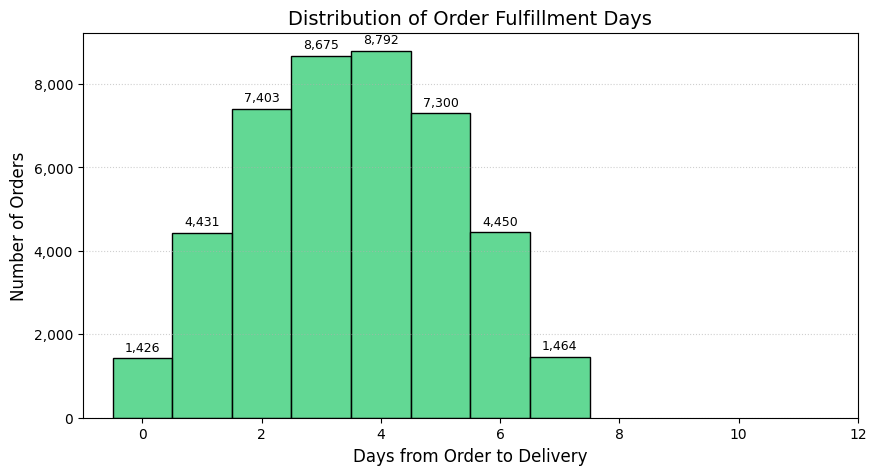

In [30]:
df['created_at'] = pd.to_datetime(df['created_at'])
df['delivered_at'] = pd.to_datetime(df['delivered_at'])

df['fulfillment_days'] = (df['delivered_at'] - df['created_at']).dt.days

valid_delivery = df[(df['fulfillment_days'].notnull()) & (df['fulfillment_days'] >= 0)]

plt.figure(figsize=(10, 5))

sns.histplot(data=valid_delivery, x='fulfillment_days', discrete=True, color='#2ecc71')
plt.title('Distribution of Order Fulfillment Days', fontsize=14)
plt.xlabel('Days from Order to Delivery', fontsize=12)
plt.ylabel('Number of Orders', fontsize=12)
plt.xlim(-1, 12)
plt.gca().yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

for p in plt.gca().patches:
    plt.gca().annotate(f'{p.get_height():,.0f}', 
                       (p.get_x() + p.get_width() / 2., p.get_height()), 
                       ha='center', va='bottom', fontsize=9, color='black', xytext=(0, 3), textcoords='offset points')
    
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.show()

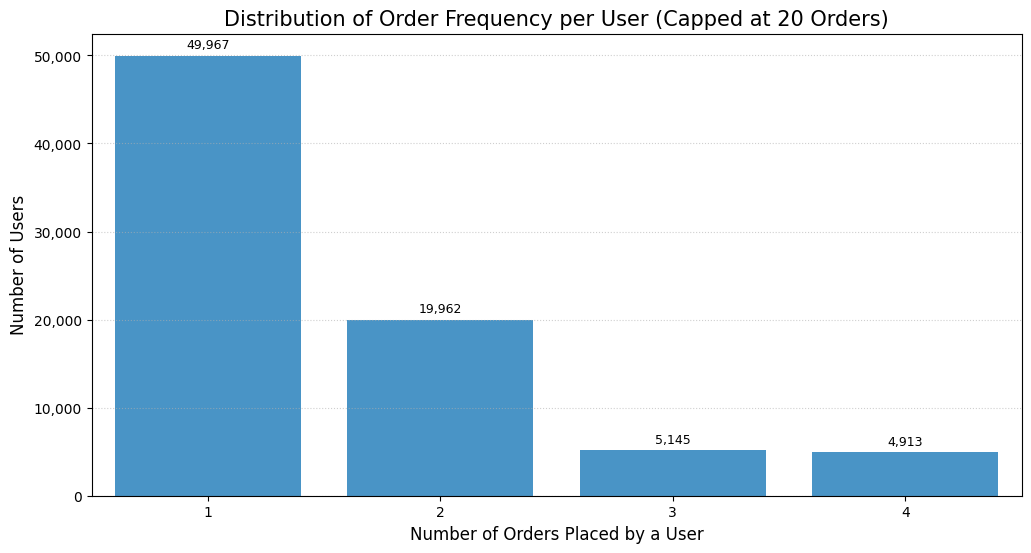

In [31]:
orders_per_user = df.groupby('user_id')['order_id'].nunique().reset_index(name='order_count')
plt.figure(figsize=(12, 6))

sns.countplot(
    data=orders_per_user[orders_per_user['order_count'] <= 20], 
    x='order_count', 
    color='#3498db'
)

plt.title('Distribution of Order Frequency per User (Capped at 20 Orders)', fontsize=15)
plt.xlabel('Number of Orders Placed by a User', fontsize=12)
plt.ylabel('Number of Users', fontsize=12)

plt.gca().yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

for p in plt.gca().patches:
    plt.gca().annotate(f'{p.get_height():,.0f}', 
                       (p.get_x() + p.get_width() / 2., p.get_height()), 
                       ha='center', va='bottom', fontsize=9, color='black', xytext=(0, 3), textcoords='offset points')

plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.show()

In [ ]:
clean_orders.to_parquet('../dataset/processed/clean_orders.parquet')

#### 2.4 order_items table

In [32]:
df= order_items.df()
df.query("" \
"   created_at > returned_at or " \
"   created_at > shipped_at or " \
"   created_at > delivered_at"
)

,id,order_id,user_id,product_id,inventory_item_id,status,created_at,shipped_at,delivered_at,returned_at,sale_price
1,150932,103936,83088,14235,407383,Shipped,2023-12-01 12:19:42,2023-11-29 19:00:59,NaT,NaT,0.02
4,28607,19698,15873,14159,77011,Complete,2023-07-31 03:59:03,2023-07-29 07:27:02,2023-07-30 11:51:02,NaT,0.49
5,44196,30424,24525,14159,119038,Shipped,2024-01-28 23:45:56,2024-01-27 11:26:47,NaT,NaT,0.49
6,81009,55722,44877,14159,218582,Shipped,2025-06-21 20:05:15,2025-06-20 13:25:42,NaT,NaT,0.49
13,10574,7338,5877,14202,28431,Complete,2023-08-23 01:44:35,2023-08-22 11:08:49,2023-08-25 17:57:49,NaT,1.50
...,...,...,...,...,...,...,...,...,...,...,...
181436,151263,104156,83266,23951,408278,Shipped,2024-12-05 14:38:32,2024-12-03 18:39:01,NaT,NaT,903.00
181438,164892,113492,90668,23654,445090,Shipped,2024-02-25 00:09:03,2024-02-23 06:22:44,NaT,NaT,903.00
181446,32769,22568,18151,24341,88221,Shipped,2025-03-17 22:58:50,2025-03-17 09:38:20,NaT,NaT,950.00
181451,111391,76583,61461,24110,300706,Shipped,2025-01-25 13:12:02,2025-01-24 01:19:46,NaT,NaT,990.00


In [33]:
duckdb.sql("""
SELECT
    MAX(created_at) - MAX(returned_at),
    MAX(created_at) - MAX(shipped_at),
    MAX(created_at) - MAX(delivered_at)
FROM
    order_items
WHERE
    created_at > returned_at or
    created_at > shipped_at or
    created_at > delivered_at
""")

┌──────────────────────────────────────┬─────────────────────────────────────┬───────────────────────────────────────┐
│ (max(created_at) - max(returned_at)) │ (max(created_at) - max(shipped_at)) │ (max(created_at) - max(delivered_at)) │
│               interval               │              interval               │               interval                │
├──────────────────────────────────────┼─────────────────────────────────────┼───────────────────────────────────────┤
│ -4 days -17:05:35.14024              │ 1 day 02:42:30.176495               │ -3 days -05:10:12.14024               │
└──────────────────────────────────────┴─────────────────────────────────────┴───────────────────────────────────────┘

**Issue Identified:** 
- During EDA, logical chronological validation (created_at > shipped_at | delivered_at) revealed 35,889 rows of dirty data in the foundational order items table that severely violate standard time sequencing.

**Diagnostic Analysis:** 
- Through time-gap investigation (with some inverted discrepancies exceeding 40 hours), the hypothesis of unaligned timezone offsets across cross-border business systems was ruled out. The root cause was determined to be a critical flaw in the data generation/entry logic of the upstream source system.

**Data Cleaning Strategy:** 
- Because our downstream Mart_Logistics_Experience requires calculating actual fulfillment duration, retaining these anomalies would yield "negative" logistics fulfillment times, completely undermining the foundation of our causal inference models. Consequently, these records were strictly dropped during the ELT transformation phase.

In [34]:
# 4. order_items
clean_order_items= duckdb.sql("""
SELECT
    id,
    order_id,
    user_id,
    inventory_item_id,
    status,
    TRY_CAST(created_at AS timestamp) AS created_at,
    TRY_CAST(shipped_at AS timestamp) AS shipped_at,
    TRY_CAST(delivered_at AS timestamp) AS delivered_at,
    TRY_CAST(returned_at AS timestamp) AS returned_at,
    sale_price
FROM order_items
WHERE
    created_at > returned_at or
    created_at > shipped_at or
    created_at > delivered_at
""")

---
**EDA**

In [35]:
df= clean_order_items.df()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35889 entries, 0 to 35888
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   id                 35889 non-null  int64         
 1   order_id           35889 non-null  int64         
 2   user_id            35889 non-null  int64         
 3   inventory_item_id  35889 non-null  int64         
 4   status             35889 non-null  object        
 5   created_at         35889 non-null  datetime64[us]
 6   shipped_at         35889 non-null  datetime64[us]
 7   delivered_at       19310 non-null  datetime64[us]
 8   returned_at        5572 non-null   datetime64[us]
 9   sale_price         35889 non-null  float64       
dtypes: datetime64[us](4), float64(1), int64(4), object(1)
memory usage: 2.7+ MB


In [36]:
df.describe()

,id,order_id,user_id,inventory_item_id,created_at,shipped_at,delivered_at,returned_at,sale_price
count,35889.000000,35889.000000,35889.000000,35889.000000,35889,35889,19310,5572,35889.000000
mean,90429.838223,62238.870629,49895.111706,244019.851403,2024-11-22 07:56:37.357293,2024-11-20 18:02:55.650865,2024-11-23 21:07:04.010446,2024-11-28 16:43:55.071986,59.122533
min,8.000000,8.000000,9.000000,22.000000,2019-01-20 20:20:47,2019-01-18 23:17:14,2019-02-12 09:07:44,2019-02-13 21:22:23,0.020000
25%,45483.000000,31320.000000,25247.000000,122544.000000,2023-11-16 08:51:06,2023-11-15 04:12:24,2023-11-22 18:33:41,2023-12-03 13:49:08,24.299999
50%,90571.000000,62317.000000,50077.000000,244416.000000,2025-05-21 17:01:27,2025-05-20 01:51:46,2025-05-20 21:59:15,2025-05-22 23:09:15,39.990002
75%,135619.000000,93362.000000,74735.000000,366010.000000,2026-04-26 11:22:00,2026-04-24 23:59:40,2026-04-25 00:39:16,2026-04-24 08:17:21.250000,69.949997
max,181463.000000,124976.000000,99998.000000,490082.000000,2026-10-12 23:55:20.723856,2026-10-11 21:12:50.547361,2026-10-16 05:05:32.864096,2026-10-17 17:00:55.864096,999.000000
std,52242.500834,35949.858908,28709.542482,141103.099327,NaN,NaN,NaN,NaN,65.153145


In [37]:
df.query("" \
"   created_at > returned_at or " \
"   created_at > shipped_at or " \
"   created_at > delivered_at"
)

,id,order_id,user_id,inventory_item_id,status,created_at,shipped_at,delivered_at,returned_at,sale_price
0,150932,103936,83088,407383,Shipped,2023-12-01 12:19:42,2023-11-29 19:00:59,NaT,NaT,0.02
1,28607,19698,15873,77011,Complete,2023-07-31 03:59:03,2023-07-29 07:27:02,2023-07-30 11:51:02,NaT,0.49
2,44196,30424,24525,119038,Shipped,2024-01-28 23:45:56,2024-01-27 11:26:47,NaT,NaT,0.49
3,81009,55722,44877,218582,Shipped,2025-06-21 20:05:15,2025-06-20 13:25:42,NaT,NaT,0.49
4,10574,7338,5877,28431,Complete,2023-08-23 01:44:35,2023-08-22 11:08:49,2023-08-25 17:57:49,NaT,1.50
...,...,...,...,...,...,...,...,...,...,...
35884,151263,104156,83266,408278,Shipped,2024-12-05 14:38:32,2024-12-03 18:39:01,NaT,NaT,903.00
35885,164892,113492,90668,445090,Shipped,2024-02-25 00:09:03,2024-02-23 06:22:44,NaT,NaT,903.00
35886,32769,22568,18151,88221,Shipped,2025-03-17 22:58:50,2025-03-17 09:38:20,NaT,NaT,950.00
35887,111391,76583,61461,300706,Shipped,2025-01-25 13:12:02,2025-01-24 01:19:46,NaT,NaT,990.00


In [ ]:
clean_order_items.to_parquet('../dataset/processed/clean_order_items.parquet')

#### 2.5 users table

In [38]:
#5. users
clean_users= duckdb.sql("""
SELECT
    id,
    first_name,
    last_name,
    COALESCE(email,'Unknown') AS email,
    COALESCE(age,null) AS age,
    COALESCE(gender,'Unknown') AS gender,
    state,
    COALESCE(street_address,'Unknown') AS street_address,
    postal_code,
    COALESCE(NULLIF(LOWER(city), 'null'), 'Unknown') AS city,
    country,
    latitude,
    longitude,
    traffic_source,
    COALESCE(created_at,null) AS created_at,
    user_geom
FROM users
""")

---
**EDA**

In [39]:
df= clean_users.df()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 16 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   id              100000 non-null  int64         
 1   first_name      100000 non-null  object        
 2   last_name       100000 non-null  object        
 3   email           100000 non-null  object        
 4   age             100000 non-null  int64         
 5   gender          100000 non-null  object        
 6   state           100000 non-null  object        
 7   street_address  100000 non-null  object        
 8   postal_code     100000 non-null  object        
 9   city            100000 non-null  object        
 10  country         100000 non-null  object        
 11  latitude        100000 non-null  float64       
 12  longitude       100000 non-null  float64       
 13  traffic_source  100000 non-null  object        
 14  created_at      100000 non-null  date

In [40]:
print(f"Extreme value of age is {df['age'].min()} and {df['age'].max() } year old")

Extreme value of age is 12 and 70 year old


In [ ]:
clean_users.to_parquet('../dataset/processed/clean_users.parquet')

### 3. Craete OBTs 
- **Frontend Traffic OBT** (clean_users + clean_events)
- **Backend Sales OBT** (clean_order_items + clean_orders + clean_inventory_items + clean_users)

In [41]:
duckdb.sql("""
SELECT
    e.id AS event_id,
    e.user_id AS user_id,
    sequence_number,
    session_id,
    e.created_at,
    e.city,
    e.state,
    COALESCE(street_address,'Unknown') AS street_address,
    browser,
    e.traffic_source,
    uri,
    event_type,
    COALESCE(NULLIF(TRIM(CONCAT(first_name, ' ', last_name)), ''), 'Unknown') AS name,
    COALESCE(email,'Unknown') AS email,
    COALESCE(age,null) AS age,
    COALESCE(gender,'Unknown') AS gender,
    COALESCE(u.created_at,null) AS user_created_at
FROM clean_events AS e
LEFT JOIN clean_users AS u ON e.user_id = u.id
ORDER BY user_id
""")

┌──────────┬─────────┬─────────────────┬──────────────────────────────────────┬─────────────────────┬───────────────────────┬──────────────────────┬────────────────┬─────────┬────────────────┬─────────────────────────────────────────────────────────────────────┬────────────┬─────────┬─────────┬───────┬─────────┬─────────────────┐
│ event_id │ user_id │ sequence_number │              session_id              │     created_at      │         city          │        state         │ street_address │ browser │ traffic_source │                                 uri                                 │ event_type │  name   │  email  │  age  │ gender  │ user_created_at │
│  int64   │  int64  │      int64      │               varchar                │      timestamp      │        varchar        │       varchar        │    varchar     │ varchar │    varchar     │                               varchar                               │  varchar   │ varchar │ varchar │ int64 │ varchar │    timestamp    │
├───

In [42]:
t1=duckdb.sql("""
SELECT
    ii.id AS inventory_item_id,
    product_id,
    ii.created_at AS inventory_items_created_at,
    sold_at,
    cost,
    product_category,
    product_name,
    product_brand,
    product_retail_price,
    product_department,
    product_sku,
    product_distribution_center_id,
    it.id AS order_items_id,
    order_id,
    user_id,
    status AS items_status,
    it.created_at AS items_created_at,
    shipped_at AS items_shipped_at,
    delivered_at AS items_delivered_at,
    returned_at AS items_returned_at,
    sale_price
FROM
    clean_inventory_items AS ii
LEFT JOIN
    clean_order_items AS it ON ii.id = it.inventory_item_id
""")

In [43]:
t2= duckdb.sql("""
SELECT
    inventory_item_id,
    product_id,
    inventory_items_created_at,
    sold_at,
    cost,
    product_category,
    product_name,
    product_brand,
    product_retail_price,
    product_department,
    product_sku,
    product_distribution_center_id,
    order_items_id,
    t1.order_id AS order_id,
    t1.user_id AS user_id,
    items_status,
    items_created_at,
    items_shipped_at,
    items_delivered_at,
    items_returned_at,
    sale_price,
    status AS orders_status,
    gender,
    created_at AS order_created_at,
    returned_at AS order_return_at,
    shipped_at AS order_shipped_at,
    delivered_at AS order_delivered_at,
    num_of_item
FROM
    t1
LEFT JOIN
    clean_orders AS o ON t1.order_id = o.order_id
""")

In [44]:
#==========================================================================================
# 1. Frontend Traffic OBT
#==========================================================================================
Frontend_Traffic_OBT =duckdb.sql("""
SELECT
    e.id AS event_id,
    e.user_id AS user_id,
    session_id,
    u.created_at AS user_created_at,
    e.created_at AS event_created_at,
    event_type,
    sequence_number,
    browser,
    u.traffic_source AS user_traffic_source,
    e.traffic_source AS event_traffic_source,
    age,
    gender,
    u.state AS user_home_state,
    e.state AS event_ip_state,
    u.city AS user_home_city,
    e.city AS event_ip_city,
    u.postal_code AS user_postal_code,
    latitude,
    longitude,
    uri
FROM clean_events AS e
LEFT JOIN clean_users AS u ON e.user_id = u.id
ORDER BY user_id
""")

#==========================================================================================
# 2. Backend Sales OBT
#==========================================================================================
Backend_Sales_OBT= duckdb.sql("""
WITH t1 AS(
    SELECT
        ii.id AS inventory_item_id,
        product_id,
        it.id AS order_items_id,
        product_distribution_center_id,
        ii.created_at AS inventory_items_created_at,
        sold_at,
        cost,
        product_category,
        product_name,
        product_brand,
        product_retail_price,
        product_department,
        product_sku,
        order_id,
        user_id,
        status AS items_status,
        it.created_at AS items_created_at,
        shipped_at AS items_shipped_at,
        delivered_at AS items_delivered_at,
        returned_at AS items_returned_at,
        sale_price
    FROM
        clean_inventory_items AS ii
    LEFT JOIN
        clean_order_items AS it ON ii.id = it.inventory_item_id
    )
SELECT
    t1.order_id AS order_id,
    order_items_id,
    inventory_item_id,
    product_id,
    t1.user_id AS user_id,
    product_distribution_center_id,
    o.created_at AS order_created_at,
    returned_at AS order_returned_at,
    shipped_at AS order_shipped_at,
    delivered_at AS order_delivered_at,
    items_created_at,
    items_returned_at,
    items_shipped_at,
    items_delivered_at,
    inventory_items_created_at,
    sold_at,
    u.created_at AS user_created_at,
    items_status,
    status AS orders_status,
    cost,
    product_retail_price,
    num_of_item,
    sale_price,
    age,
    u.gender,
    product_brand,
    product_department,
    product_category,
    product_name,
    traffic_source,
    state,
    postal_code,
    country,
    city,
    latitude,
    longitude,
    product_sku
FROM
    t1
LEFT JOIN
    clean_orders AS o ON t1.order_id = o.order_id
LEFT JOIN
    clean_users AS u ON t1.user_id = u.id
""")

In [ ]:
Frontend_Traffic_OBT.to_parquet('../dataset/processed/Frontend_Traffic_OBT.parquet')
Backend_Sales_OBT.to_parquet('../dataset/processed/Backend_Sales_OBT.parquet')

### 4. Create Data Marts

#### 4.1 **Mart Financial Summary** （用季度总营收和售罄率）
**财务分析摘要框架**(时间维度 (The Dimension))
1. 规模与体量指标 (Volume Metrics)
2. 核心财务指标 (Financial Metrics - 钱)
3. 业务健康度与效率指标 (Health Ratios - 比例)

##### 4.1.1 ***Volume Metrics***

- 季度活跃买家数 (Quarterly Active Buyers)：这个季度内有多少个独立用户 (user_id 去重) 下了单。
- 总订单量 (Total Orders)：这个季度一共产生了多少笔独立的订单。
- 商品售出总件数 (Total Items Sold)：这个季度一共卖出去了多少件商品。

In [45]:
duckdb.sql("""
SELECT
    CONCAT(YEAR(order_created_at), '-Q', QUARTER(order_created_at)) AS Year_Quarter,
    CONCAT('Q',QUARTER(order_created_at)) AS Quarter,
    YEAR(order_created_at) AS Year,
    COUNT(DISTINCT(user_id)) AS Active_Buyers,
    COUNT(DISTINCT(order_id)) AS Total_Orders,
    COUNT(order_items_id) AS Total_Items_Sold
FROM
    Backend_Sales_OBT
WHERE
    user_id IS NOT NULL
GROUP BY
    YEAR(order_created_at),QUARTER(order_created_at)
ORDER BY
    Year,QUARTER(order_created_at)
""")

┌──────────────┬─────────┬───────┬───────────────┬──────────────┬──────────────────┐
│ Year_Quarter │ Quarter │ Year  │ Active_Buyers │ Total_Orders │ Total_Items_Sold │
│   varchar    │ varchar │ int64 │     int64     │    int64     │      int64       │
├──────────────┼─────────┼───────┼───────────────┼──────────────┼──────────────────┤
│ 2019-Q1      │ Q1      │  2019 │            10 │           10 │               15 │
│ 2019-Q2      │ Q2      │  2019 │            32 │           32 │               53 │
│ 2019-Q3      │ Q3      │  2019 │            47 │           47 │               79 │
│ 2019-Q4      │ Q4      │  2019 │            81 │           81 │              141 │
│ 2020-Q1      │ Q1      │  2020 │           105 │          105 │              179 │
│ 2020-Q2      │ Q2      │  2020 │           132 │          132 │              236 │
│ 2020-Q3      │ Q3      │  2020 │           149 │          150 │              258 │
│ 2020-Q4      │ Q4      │  2020 │           164 │          164 │

##### 4.1.2 ***Financial Metrics***

- 总流水 (GMV)：所有产生交易的商品按售价加总的金额。
- 净营业额 (Net Revenue) 【重要新增】：GMV - 退款金额 - 取消金额。在 TheLook 数据集中，你需要剔除 status 为 Returned 和 Cancelled 的订单金额。这是比 GMV 更真实的进账。
- 总销货成本 (COGS)：将 order_items 表与 inventory_items 表进行 JOIN，获取每件售出商品的真实拿货成本 (cost) 并加总。
- 真实毛利润 (Gross Profit) 【逻辑修改】：用 净营业额 减去总成本。如果你用 GMV 减成本，算出来的账面利润是虚高的（因为包含了退货商品的钱）。

In [46]:
duckdb.sql("""
SELECT
    CONCAT(YEAR(order_created_at), '-Q', QUARTER(order_created_at)) AS Year_Quarter,
    YEAR(order_created_at) AS Year,
    CONCAT('Q', QUARTER(order_created_at)) AS Quarter,
    ROUND(SUM(CASE WHEN items_status = 'Returned' THEN sale_price ELSE 0 END), 4) AS Return_Amount,
    ROUND(SUM(CASE WHEN items_status = 'Cancelled' THEN sale_price ELSE 0 END), 4) AS Cancelled_Amount,
    ROUND(SUM(sale_price), 4) AS GMV,
    ROUND(SUM(CASE WHEN items_status NOT IN ('Returned', 'Cancelled') THEN sale_price ELSE 0 END), 4) AS Net_Revenue,
    ROUND(SUM(CASE WHEN items_status NOT IN ('Returned', 'Cancelled') THEN cost ELSE 0 END), 4) AS COGS,
    ROUND(SUM(CASE WHEN items_status NOT IN ('Returned', 'Cancelled') THEN (sale_price - cost) ELSE 0 END), 4) AS Gross_Profit
FROM Backend_Sales_OBT
WHERE
    user_id IS NOT NULL
GROUP BY
    YEAR(order_created_at), QUARTER(order_created_at)
ORDER BY
    Year, Quarter
""")

┌──────────────┬───────┬─────────┬───────────────┬──────────────────┬─────────────┬─────────────┬─────────────┬──────────────┐
│ Year_Quarter │ Year  │ Quarter │ Return_Amount │ Cancelled_Amount │     GMV     │ Net_Revenue │    COGS     │ Gross_Profit │
│   varchar    │ int64 │ varchar │    double     │      double      │   double    │   double    │   double    │    double    │
├──────────────┼───────┼─────────┼───────────────┼──────────────────┼─────────────┼─────────────┼─────────────┼──────────────┤
│ 2019-Q1      │  2019 │ Q1      │         327.0 │              0.0 │      758.45 │      431.45 │    497.0292 │     -65.5792 │
│ 2019-Q2      │  2019 │ Q2      │        444.25 │              0.0 │     3187.22 │     2742.97 │   1289.7655 │    1453.2045 │
│ 2019-Q3      │  2019 │ Q3      │        616.44 │              0.0 │     5663.16 │     5046.72 │    2068.841 │     2977.879 │
│ 2019-Q4      │  2019 │ Q4      │       1085.17 │              0.0 │      7695.4 │     6610.23 │   2882.8532 │

##### 4.1.3 ***Health Ratios***

- 毛利率 (Gross Margin %)：毛利润 / 净营业额。衡量业务盈利模式是否健康的终极指标。
- 客单价 (AOV - Average Order Value)：单季度 总流水 / 总订单量。
- 平均单客产出 (ARPU) 【重要新增】：单季度 净营业额 / 季度活跃买家数。客单价看的是“单次交易价值”，ARPU 看的是“单个用户的季度商业价值”。
- 退货率 (Return Rate %)：状态为“已退货”的商品件数占比。

In [47]:
duckdb.sql("""
SELECT
    CONCAT(YEAR(order_created_at), '-Q', QUARTER(order_created_at)) AS Year_Quarter,
    YEAR(order_created_at) AS Year,
    CONCAT('Q', QUARTER(order_created_at)) AS Quarter,
    ROUND(100.0*SUM(CASE WHEN items_status NOT IN('Returned','Cancelled') THEN (sale_price-cost)END) / NULLIF(SUM(CASE WHEN items_status NOT IN('Returned','Cancelled') THEN (sale_price)END),0),4) AS "Gross_Margin(%)",
    ROUND(SUM(sale_price)/COUNT(DISTINCT order_id),4) AS AOV,
    ROUND(SUM(CASE WHEN items_status NOT IN('Returned','Cancelled') THEN (sale_price)END) / NULLIF(COUNT(DISTINCT user_id),0),4) AS ARPU,
    ROUND(100.0 * SUM(CASE WHEN items_status = 'Returned' THEN 1 ELSE 0 END) / NULLIF(COUNT(order_items_id),0),4) AS "Return_Rate(%)",
FROM
    Backend_Sales_OBT
WHERE
    user_id IS NOT NULL
GROUP BY
    YEAR(order_created_at),QUARTER(order_created_at)
ORDER BY
    Year,Quarter
""")

┌──────────────┬───────┬─────────┬─────────────────┬──────────┬─────────┬────────────────┐
│ Year_Quarter │ Year  │ Quarter │ Gross_Margin(%) │   AOV    │  ARPU   │ Return_Rate(%) │
│   varchar    │ int64 │ varchar │     double      │  double  │ double  │     double     │
├──────────────┼───────┼─────────┼─────────────────┼──────────┼─────────┼────────────────┤
│ 2019-Q1      │  2019 │ Q1      │        -15.1997 │   75.845 │  43.145 │           20.0 │
│ 2019-Q2      │  2019 │ Q2      │         52.9792 │  99.6006 │ 85.7178 │        16.9811 │
│ 2019-Q3      │  2019 │ Q3      │         59.0062 │ 120.4928 │ 107.377 │        13.9241 │
│ 2019-Q4      │  2019 │ Q4      │          56.388 │  95.0049 │ 81.6078 │        16.3121 │
│ 2020-Q1      │  2020 │ Q1      │         54.3616 │    95.95 │ 85.2249 │        13.4078 │
│ 2020-Q2      │  2020 │ Q2      │         47.9124 │ 109.7353 │  99.378 │        10.5932 │
│ 2020-Q3      │  2020 │ Q3      │         53.7709 │ 106.8348 │ 94.6515 │        14.3411 │

- 退款折损金额 (Value of Returns)：单独把退货吃掉的销售额算出来。直接在财报上展示“因为退货，本季度流失了多少潜在营收”，这对业务部门非常有视觉冲击力。

In [48]:
duckdb.sql("""
SELECT
    CONCAT(YEAR(order_created_at), '-Q', QUARTER(order_created_at)) AS Year_Quarter,
    YEAR(order_created_at) AS Year,
    CONCAT('Q', QUARTER(order_created_at)) AS Quarter,
    ROUND(SUM(CASE WHEN items_status = 'Returned' THEN sale_price ELSE 0 END),4) AS Value_Of_Returns
FROM
    Backend_Sales_OBT
WHERE
    user_id IS NOT NULL
GROUP BY
    YEAR(order_created_at),QUARTER(order_created_at)
ORDER BY
    Year,Quarter
""")

┌──────────────┬───────┬─────────┬──────────────────┐
│ Year_Quarter │ Year  │ Quarter │ Value_Of_Returns │
│   varchar    │ int64 │ varchar │      double      │
├──────────────┼───────┼─────────┼──────────────────┤
│ 2019-Q1      │  2019 │ Q1      │            327.0 │
│ 2019-Q2      │  2019 │ Q2      │           444.25 │
│ 2019-Q3      │  2019 │ Q3      │           616.44 │
│ 2019-Q4      │  2019 │ Q4      │          1085.17 │
│ 2020-Q1      │  2020 │ Q1      │          1126.14 │
│ 2020-Q2      │  2020 │ Q2      │          1367.17 │
│ 2020-Q3      │  2020 │ Q3      │          1922.14 │
│ 2020-Q4      │  2020 │ Q4      │          3000.12 │
│ 2021-Q1      │  2021 │ Q1      │           2861.2 │
│ 2021-Q2      │  2021 │ Q2      │          3321.02 │
│    ·         │    ·  │ ·       │             ·    │
│    ·         │    ·  │ ·       │             ·    │
│    ·         │    ·  │ ·       │             ·    │
│ 2024-Q3      │  2024 │ Q3      │         10942.93 │
│ 2024-Q4      │  2024 │ Q4 

##### 4.1.4 **Conclusion**

In [49]:
mart_financial_summary= duckdb.sql("""
WITH Base_Metrics AS (
    SELECT
        CONCAT(YEAR(order_created_at), '-Q', QUARTER(order_created_at)) AS year_quarter,
        CONCAT('Q', QUARTER(order_created_at)) AS quarter,
        YEAR(order_created_at) AS year,

        COUNT(DISTINCT user_id) AS active_buyers,
        COUNT(DISTINCT order_id) AS total_orders,
        COUNT(order_items_id) AS total_items_sold,

        SUM(CASE WHEN items_status = 'Returned' THEN 1 ELSE 0 END) AS returned_items_count,

        SUM(sale_price) AS GMV,
        SUM(CASE WHEN items_status = 'Returned' THEN sale_price ELSE 0 END) AS return_amount,
        
        SUM(CASE WHEN items_status NOT IN ('Returned', 'Cancelled') THEN sale_price ELSE 0 END) AS net_revenue,
        SUM(CASE WHEN items_status NOT IN ('Returned', 'Cancelled') THEN cost ELSE 0 END) AS COGS

    FROM Backend_Sales_OBT
    WHERE user_id IS NOT NULL
    GROUP BY YEAR(order_created_at), QUARTER(order_created_at)
)

SELECT
    year_quarter,
    quarter,
    year,
    active_buyers,
    total_orders,
    total_items_sold,

    ROUND(return_amount, 2) AS return_amount,
    ROUND(GMV, 2) AS GMV,
    ROUND(net_revenue, 2) AS net_revenue,
    ROUND(COGS, 2) AS COGS,
    ROUND(net_revenue - COGS, 2) AS gross_profit,

    ROUND(100.0 * (net_revenue - COGS) / NULLIF(net_revenue, 0), 2) AS gross_margin_pct,
    ROUND(GMV / NULLIF(total_orders, 0), 2) AS AOV,
    ROUND(net_revenue / NULLIF(active_buyers, 0), 2) AS ARPU,
    ROUND(100.0 * returned_items_count / NULLIF(total_items_sold, 0), 2) AS return_rate_pct,

FROM Base_Metrics
ORDER BY Year, Quarter
""")


In [ ]:
mart_financial_summary.to_parquet('../dataset/processed/mart_financial_summary.parquet')

#### 4.2 **Mart RFM Segmentation** （精准圈定你的实验受众与高价值客群）

##### 4.2.1 计算 RFM 绝对值

In [50]:
#过滤条件： 记住，必须剔除 Cancelled 和 Returned 的订单记录，只算真实的有效营收。
#R (Recency - 最近一次消费时间)：
#你需要思考的难点： 我们不能用“今天”去减去购买时间，因为这是一份历史数据集。你需要去找到整个数据集里“最后一笔订单发生的那一天”作为基准日（Reference Date），然后算出每个用户的最后一次购买日期距离这个基准日有多少天。

#F (Frequency - 消费频次)：
#你需要思考的难点： 频次是指“订单数”还是“商品件数”？在标准商业逻辑里，通常是计算去重的有效订单总数。

#M (Monetary - 消费总额)：
#用户的历史有效净消费总额。

In [51]:
RFM = duckdb.sql("""
WITH t AS(
    SELECT
        MAX(order_created_at) AS global_max_date
    FROM Backend_Sales_OBT
)
SELECT
    CONCAT(YEAR(order_created_at), '-Q', QUARTER(order_created_at)) AS Year_Quarter,
    user_id,
    DATEDIFF('day',MAX(order_created_at), (SELECT global_max_date FROM t)) AS recency,
    COUNT(DISTINCT order_id) AS frequency,
    ROUND(SUM(sale_price),2) AS monetary
FROM Backend_Sales_OBT
WHERE
    items_status NOT IN ('Cancelled','Returned') AND 
    user_id IS NOT NULL AND 
    order_created_at >= (SELECT global_max_date - INTERVAL 1 YEAR FROM t)
GROUP BY
    user_id,YEAR(order_created_at),QUARTER(order_created_at)
ORDER BY
    recency,frequency desc,monetary desc
""")

##### 4.2.2 打分机制

In [52]:
#第二步：打分机制 (Scoring - 你的进阶挑战)
    #算出天数、次数和金额后，你不能直接拿绝对值去分层。你需要去学习并实现一个机制：将这三个绝对值转换为 1-4 分或 1-5 分的相对分值（Score）。
    #你需要去自学的关键词 (Hints)：
    #如果你想用 SQL 实现：去查一下窗口函数 NTILE(4) 或 PERCENT_RANK()。
    #如果你想用 Python 实现：去查一下 Pandas 里的 pd.qcut()。
    # F（频次）和 M（金额）是越大越好（分位值越高，分数越高）；但 R（最近消费天数）是越小越好（距今越近，证明越活跃，分位值越低，分数反而应该越高）。这是无数初学者都会掉进去的坑！

In [ ]:
RFM2 = duckdb.sql("""
SELECT
    *,
    NTILE(5) OVER (ORDER BY recency DESC) AS r_score,
    NTILE(5) OVER (ORDER BY frequency ASC) AS f_score,
    NTILE(5) OVER (ORDER BY monetary ASC) AS m_score
FROM RFM
""")

##### 4.2.3 业务分层 (Segmentation)

In [54]:
#第三步：业务分层 (Segmentation)
    #当你拿到每个人的 R_Score, F_Score, M_Score (例如：某用户是 R=4, F=1, M=1) 后，你需要定义一套业务规则给他们贴上人类能看懂的标签。
    #你需要去构思的标签（参考）：
    #Champions (核心忠诚客)： R, F, M 都是最高分。（你的重点维护对象）
    #At Risk (面临流失的高价值客)： F和M都很高，但 R 很低（很久没来了）。（这就是你接下来做 A/B 测试发放“挽回优惠券”的精准目标群体！）
    #Hibernating (沉睡低价值客)： R, F, M 都是最低分。

In [ ]:
mart_rfm_segmentation= duckdb.sql("""
WITH Max_Date AS (
    SELECT MAX(order_created_at) AS global_max_date
    FROM Backend_Sales_OBT
),
RFM_Base AS (
    SELECT 
        CONCAT(YEAR(order_created_at), '-Q', QUARTER(order_created_at)) AS Year_Quarter,
        user_id,
        DATEDIFF('day', MAX(order_created_at), (SELECT global_max_date FROM Max_Date)) AS recency,
        COUNT(DISTINCT order_id) AS frequency,
        ROUND(SUM(sale_price), 2) AS monetary
    FROM Backend_Sales_OBT
    WHERE items_status NOT IN ('Cancelled','Returned') 
      AND user_id IS NOT NULL 
      AND order_created_at >= (SELECT global_max_date - INTERVAL 1 YEAR FROM Max_Date)
    GROUP BY user_id, YEAR(order_created_at), QUARTER(order_created_at)
),
RFM_Scores AS (
    SELECT 
        *,
        NTILE(5) OVER (PARTITION BY Year_Quarter ORDER BY recency DESC) AS r_score,
        NTILE(5) OVER (PARTITION BY Year_Quarter ORDER BY frequency ASC) AS f_score,
        NTILE(5) OVER (PARTITION BY Year_Quarter ORDER BY monetary ASC) AS m_score
    FROM RFM_Base
)
SELECT 
    *,
    CASE
        WHEN r_score >= 4 AND f_score >= 4 AND m_score >= 4 THEN 'Champions'
        WHEN r_score = 1 AND f_score >= 4 AND m_score >= 4 THEN 'Cant Lose Them' 
        WHEN r_score >= 3 AND f_score >= 3 AND m_score >= 3 THEN 'Loyalists'
        WHEN r_score >= 4 AND f_score = 1 THEN 'New Customers'
        WHEN r_score >= 3 AND f_score <= 3 THEN 'Potential Loyalists' 
        WHEN r_score IN (2, 3) AND f_score IN (2, 3) THEN 'Need Attention'
        WHEN r_score <= 2 AND f_score >= 2 AND m_score >= 2 THEN 'At Risk'
        WHEN r_score <= 2 AND f_score >= 4 AND m_score <= 2 THEN 'Lost Bargain Hunters'
        WHEN r_score <= 2 AND f_score <= 2 AND m_score <= 2 THEN 'Hibernating / Lost'
        ELSE 'Others' 
    END AS rfm_segment
FROM RFM_Scores
ORDER BY Year_Quarter, r_score DESC, f_score DESC, m_score DESC
""")

In [ ]:
mart_rfm_segmentation.to_parquet('../dataset/processed/mart_rfm_segmentation.parquet')

┌──────────────┬─────────┬─────────┬───────────┬──────────┬─────────┬─────────┬─────────┬────────────────────┐
│ Year_Quarter │ user_id │ recency │ frequency │ monetary │ r_score │ f_score │ m_score │    rfm_segment     │
│   varchar    │  int64  │  int64  │   int64   │  double  │  int64  │  int64  │  int64  │      varchar       │
├──────────────┼─────────┼─────────┼───────────┼──────────┼─────────┼─────────┼─────────┼────────────────────┤
│ 2025-Q4      │    3150 │     284 │         2 │   260.08 │       5 │       5 │       5 │ Champions          │
│ 2025-Q4      │   99736 │     283 │         1 │   167.99 │       5 │       5 │       5 │ Champions          │
│ 2025-Q4      │   93439 │     288 │         1 │    600.0 │       5 │       5 │       5 │ Champions          │
│ 2025-Q4      │   66234 │     297 │         1 │   264.95 │       5 │       5 │       5 │ Champions          │
│ 2025-Q4      │   36961 │     297 │         1 │    265.0 │       5 │       5 │       5 │ Champions          │
│

#### 4.3 **Mart_Logistics_Experience** （通过你坚持保留的 Item 时间戳，量化糟糕的物流体验对留存的真实负面影响）

1. 确定表的粒度 (Grain)
- 基础表： Backend_Sales_OBT
- 聚合维度 (GROUP BY)： 必须是 order_id （连带 user_id 也要保留，方便之后跟你的 RFM 联动）。你的每一行数据，应该代表“一笔完整的订单”。
- 过滤条件： 你只需要分析已经成功发货并送达的订单。未发货、或者直接被取消的订单没有“物流体验”可言，应该在 WHERE 阶段过滤掉。

2. 你需要计算的核心字段 (The "What")
- 你需要从多件商品的明细中，浓缩出以下 5 个关键的物流体验指标：
- 指标 A：订单包含的商品件数 (买得多，拆单概率自然大)。
- 指标 B：发货仓库数量 (DC Count)。
- 业务意义： 如果一笔订单是从 2 个或以上的不同 Distribution Center 发出的，这就是绝对意义上的“拆单发货”。
- 指标 C：整体履约耗时 (Total Fulfillment Time)。
- 业务意义： 从用户按下“支付 (order_created_at)”那一刻，到“最后一件商品送达”的总等待时长。
- 指标 D：因果推断的结果变量 (Return Flag / 退货标记)
- 业务意义： 在这笔订单中，用户最终有没有退货？（是 = 1，否 = 0）。这就是你未来要送进 Python 验证“物流差是否导致退货”的 Target Variable。

In [57]:
duckdb.sql("""
SELECT
    *
FROM
    Backend_Sales_OBT
""")

┌──────────┬────────────────┬───────────────────┬────────────┬─────────┬────────────────────────────────┬─────────────────────┬─────────────────────┬─────────────────────┬─────────────────────┬─────────────────────┬─────────────────────┬─────────────────────┬─────────────────────┬────────────────────────────┬─────────────────────┬─────────────────────┬──────────────┬───────────────┬────────────────────┬──────────────────────┬─────────────┬────────────────────┬───────┬─────────┬──────────────────────┬────────────────────┬──────────────────┬─────────────────────────────────────────────────────────────────────┬────────────────┬─────────────────────┬─────────────┬───────────────┬────────────────────┬──────────────┬──────────────┬──────────────────────────────────┐
│ order_id │ order_items_id │ inventory_item_id │ product_id │ user_id │ product_distribution_center_id │  order_created_at   │  order_returned_at  │  order_shipped_at   │ order_delivered_at  │  items_created_at   │  items_return

In [58]:
mart_logistics_experience= duckdb.sql("""
SELECT
    user_id,
    order_id,
    COUNT(DISTINCT order_items_id) AS total_items,
    COUNT(DISTINCT product_distribution_center_id) AS total_dc,
    DATEDIFF('hour',MIN(order_created_at),MAX(items_delivered_at)) AS total_fulfillment_time_hours,
    MAX(CASE WHEN orders_status = 'Returned' THEN 1 ELSE 0 END) AS return_flag
FROM
    Backend_Sales_OBT
WHERE
    user_id IS NOT NULL AND items_delivered_at IS NOT NULL 
GROUP BY
    order_id,user_id
ORDER BY user_id 
""")

In [ ]:
mart_logistics_experience.to_parquet('../dataset/processed/mart_logistics_experience.parquet')

#### 4.4 **Mart_Experimentation_Base**（针对上述痛点模拟一个改善策略，通过 A/B 测试检验 ROI）

- 字段 A：user_id (样本 ID)
- 字段 B：experiment_group (实验组别)
-- 直接取用户的 traffic_source（比如 'Facebook', 'Organic' 等），这将是你未来 Python 里切分 Treatment 和 Control 组的依据。
- 字段 C：total_page_views (前端活跃度): 该用户在前端一共产生了多少条 event 记录？
- 字段 D：is_converted (转化标记 - 核心 Target 1): 该用户到底有没有下单？（如果有后端的订单，就是 1；如果光看不买，就是 0）。
- 字段 E：total_spend (消费金额 - 核心 Target 2): 该用户一共花了多少钱？（如果没下单，金额必须是 0，绝对不能是 NULL，否则 Python 跑方差时直接崩溃报错）。

In [ ]:
mart_experimentation_base= duckdb.sql("""
WITH frontend_agg AS (
    SELECT 
        user_id,
        ANY_VALUE(user_traffic_source) AS experiment_group,
        COUNT(event_id) AS totaal_page_view
    FROM Frontend_Traffic_OBT
    GROUP BY user_id
),
backend_agg AS (
    SELECT
        user_id,
        SUM(sale_price) AS total_spend
    FROM Backend_Sales_OBT
    GROUP BY user_id
)
SELECT
    f.user_id,
    f.experiment_group,
    f.total_page_view,
    CASE WHEN b.user_id IS NOT NULL THEN 1 ELSE 0 END AS is_converted,
    COALESCE(b.total_spend, 0) AS total_spend

FROM frontend_agg AS f
LEFT JOIN backend_agg AS b 
    ON f.user_id = b.user_id
ORDER BY user_id
""")

In [ ]:
mart_experimentation_base.to_parquet('../dataset/processed/mart_experimentation_base.parquet')

#### 4.5 **Mart_Impulse_Penalty**

In [62]:
#1. 确定表的粒度 (Grain)
#基础表： Frontend_Traffic_OBT
#聚合维度 (GROUP BY)： 必须是 session_id。每一行代表用户的一次“进店逛街”。为了方便后续关联，把 user_id 也放进 GROUP BY 里（因为一个 session 绝对只对应一个 user）。

#2. 你需要计算的核心字段 (The "What")
#指标 A：user_id & session_id (基础主键)
#指标 B：session_duration_minutes (会话总时长)
#业务意义： 逛了多久？你需要算出该 session 内最后一次点击和第一次点击的分钟差。
#指标 C：total_page_views (浏览深度)
#业务意义： 逛了多少个页面？也就是计算该 session 内有多少条 event 记录。
#指标 D：search_and_product_clicks (高意图动作次数)
#业务意义： 在 TheLook 的前端数据里，event_type 通常有 home, department, product, search, cart, purchase 等。如果一个用户频繁使用 search (搜索) 或者查看具体的 product (商品详情页)，说明他是有备而来。你需要统计这两类动作的出现次数。
#指标 E：is_purchase_session (转化标记 - Target Variable)
#业务意义： 这一次进店，最终掏钱了吗？如果该 session 里出现过 event_type = 'purchase'，则标记为 1，否则为 0。

In [ ]:
mart_session_intent = duckdb.sql("""
WITH session_aggregated AS (
    SELECT 
        session_id,
        MAX(user_id) AS user_id, 
        DATE_DIFF('minute', MIN(created_at), MAX(created_at)) AS session_duration_minutes,
        COUNT(id) AS total_page_views,
        SUM(CASE WHEN event_type IN ('product', 'cart', 'department') THEN 1 ELSE 0 END) AS high_intent_clicks,
        MAX(CASE WHEN event_type = 'purchase' THEN 1 ELSE 0 END) AS is_purchase_session
    FROM events
    GROUP BY session_id
)

SELECT * 
FROM session_aggregated 
WHERE is_purchase_session = 1
""")

In [64]:
mart_impulse_penalty = duckdb.sql("""
WITH intent_tagged AS (
    SELECT 
        session_id,
        user_id,
        session_duration_minutes,
        CASE 
            WHEN session_duration_minutes < 10 AND total_page_views <= 6 THEN 'Impulse Buyers'
            WHEN session_duration_minutes > 60 OR total_page_views >= 12 THEN 'Heavy Browsers'
            ELSE 'Targeted Searchers'
        END AS user_intent
    FROM mart_session_intent
),
session_with_orders AS (
    SELECT 
        i.user_intent,
        i.session_duration_minutes,
        CASE WHEN o.items_status = 'Returned' THEN 1.0 ELSE 0.0 END AS is_returned
    FROM intent_tagged i
    JOIN Backend_Sales_OBT o ON i.user_id = o.user_id 
)

SELECT 
    user_intent AS User_Intent,
    AVG(is_returned) AS Return_Rate,
    AVG(CASE WHEN session_duration_minutes < 120 THEN session_duration_minutes ELSE 120 END) AS Avg_Session_Mins,
    COUNT(*) AS volume
FROM session_with_orders
GROUP BY user_intent
ORDER BY Return_Rate DESC
""")
mart_impulse_penalty.df()

,User_Intent,Return_Rate,Avg_Session_Mins,volume
0,Impulse Buyers,0.157737,5.878601,25758
1,Targeted Searchers,0.154466,10.533074,11051
2,Heavy Browsers,0.152812,113.526241,115259


In [ ]:
mart_impulse_penalty.to_parquet('../dataset/processed/mart_impulse_penalty.parquet')

### 5. Mart_Logistics_Experience A/B test

#### README

##### EDA 与因果前瞻分析规划：物流体验与用户意图探索
**核心分析目标**:
- 通过视觉化手段，证明“物流延迟”会导致“退货率升高”，并探究“不同购买意图的用户”对物流延迟的敏感度差异，最终为 A/B 测试锁定高价值的干预群体。
1. ***深挖供应链痛点*** (The "Why" behind delays)
- 图表 1：拆单发货对履约时效的物理影响
- 推荐图表： Seaborn 小提琴图 (Violin Plot) 或 箱线图 (Boxplot)带散点 (sns.boxplot + sns.stripplot)。
- X 轴 (类别)： is_split_shipment (衍生特征：total_dc > 1 为 True，即拆单发货；total_dc == 1 为 False，即单仓发货)。
- Y 轴 (数值)： total_fulfillment_time_hours (履约总耗时)。
- 商业目的： 向业务团队视觉化地证明，多仓拆单发货不仅增加了运费成本，还在物理上极其显著地拖慢了送达时间。
- 预期见解 (Insights)： 拆单发货的订单，其中位数送达时间比单仓发货长 X 小时，且时间分布的尾部（极端延迟）极长。这就是我们需要被“干预”的病灶。

2. ***量化等待的代价*** (The Cost of Waiting)
- 图表 2：物流耗时与退货概率的非线性关系
- 推荐图表： 分箱折线图带置信区间 (sns.lineplot) 或 带有回归拟合的散点图 (sns.regplot)。
- X 轴 (数值分箱)： binned_fulfillment_time (将耗时按 24h, 48h, 72h, 96h+ 进行分桶预处理)。
- Y 轴 (均值)： Return Rate (return_flag 的平均值)。
- 商业目的： 找到用户的“耐心临界点 (Patience Threshold)”。到底超过几天没收到货，用户的心态会崩盘并决定退货？
- 预期见解 (Insights)： 退货率并不是随时间线性增长的。我们可能会发现一个“拐点”——比如在 72 小时内送达，退货率稳定在 10%；一旦超过 72 小时，退货率呈指数级飙升至 25%。这个“72小时”就是未来运营团队的生死线。

3. ***引入意图特征进行异质性分析*** (Heterogeneous Treatment Effect)(注：此阶段需要将 Mart_Logistics_Experience 与 Mart_Session_Intent 通过 user_id 进行 Merge)
- 图表 3：不同意图用户的“冲动惩罚” (Impulse Penalty)
- 推荐图表： 分组柱状图 (sns.barplot)。
- X 轴 (类别)： Intent Segment (高意图-搜索型 vs. 低意图-闲逛型)。
- Hue (分色)： Delivery Speed (基于图表2的拐点，切分为 Fast vs. Slow)。
- Y 轴 (均值)： Return Rate。
- 商业目的： 证明并非所有用户对物流延迟的容忍度都一样。闲逛型用户（冲动消费）如果在冲动劲过去后还没收到货，退货概率极高；而搜索型用户（刚需消费）即使物流慢，一般也会咬牙收下。
- 预期见解 (Insights)： 柱状图将清晰显示巨大的“交叉效应 (Interaction Effect)”。慢物流对“闲逛型”用户的退货率惩罚，远大于对“高意图”用户的惩罚。

4. ***通往 A/B 测试的桥梁*** (Bridge to Experimentation)
- 基于上述图表得出的深刻洞察，我们的 A/B 测试策略将不再是盲目的全量发券，而是精准的 精准定向干预 (Targeted Intervention)：
- 实验假设 (Hypothesis)： 针对识别为“低意图/闲逛型”的用户，如果在结算页面为其提供“免邮升舱服务 (Priority Shipping Upgrade)”（缩短预期时间至 48h 内），能够显著抑制其冲动消退带来的高退货率，最终提升这批人群的真实 ARPU (每用户平均净营收)。
- 模型对接： 这些可视化的特征（意图标签、拆单标记）将直接作为你后续 Python 统计检验模型里的协变量 (Covariates)。

#### 5.1 **深挖供应链痛点**

C:\Users\user\AppData\Local\Temp\ipykernel_18836\2496451387.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  return_rates = df_logistics.groupby('fulfillment_bin')['return_flag'].mean().reset_index()
C:\Users\user\AppData\Local\Temp\ipykernel_18836\2496451387.py:10: UserWarning: 

The `scale` parameter is deprecated and will be removed in v0.15.0. You can now control the size of each plot element using matplotlib `Line2D` parameters (e.g., `linewidth`, `markersize`, etc.).

  ax = sns.pointplot(


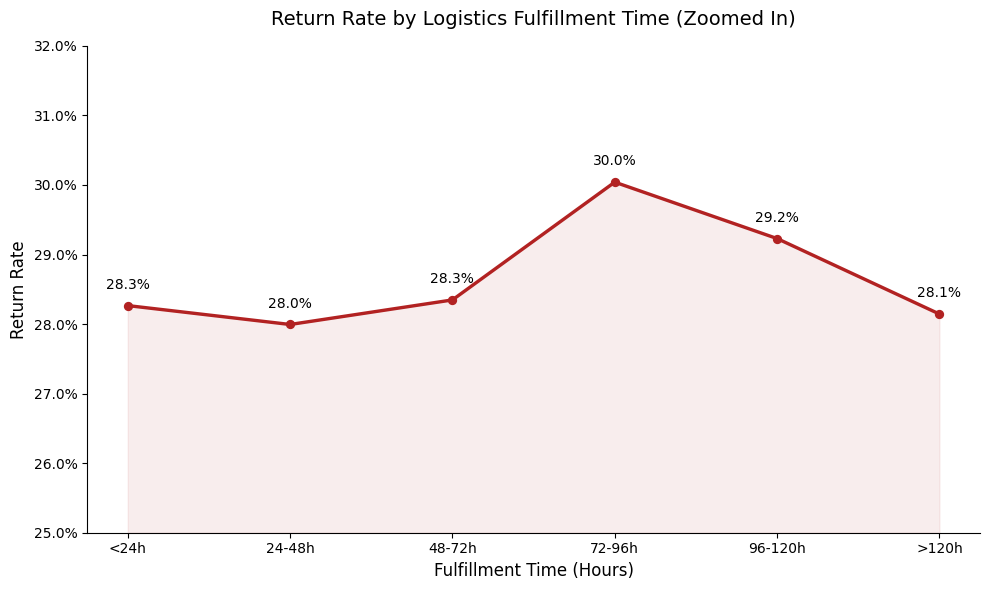

In [75]:
df_logistics = mart_logistics_experience.df()
bins = [0, 24, 48, 72, 96, 120, np.inf]
labels = ['<24h', '24-48h', '48-72h', '72-96h', '96-120h', '>120h']
df_logistics['fulfillment_bin'] = pd.cut(df_logistics['total_fulfillment_time_hours'], bins=bins, labels=labels)
return_rates = df_logistics.groupby('fulfillment_bin')['return_flag'].mean().reset_index()

plt.figure(figsize=(10, 6))
primary_color = '#B22222'

ax = sns.pointplot(
    data=return_rates, 
    x='fulfillment_bin', 
    y='return_flag', 
    color=primary_color, 
    markers='o', 
    linestyles='-',
    scale=0.9
)

ax.set_ylim(0.25, 0.32)
ax.yaxis.set_major_formatter(ticker.PercentFormatter(1.0))

x_indices = np.arange(len(return_rates))
plt.fill_between(
    x_indices, 
    return_rates['return_flag'], 
    0.25,
    color=primary_color, 
    alpha=0.08,
    interpolate=True
)

for i, point in enumerate(return_rates['return_flag']):
    ax.text(i, point + 0.002, f'{point:.1%}', ha='center', va='bottom', fontsize=10)

plt.title('Return Rate by Logistics Fulfillment Time (Zoomed In)', fontsize=14, pad=15)
plt.xlabel('Fulfillment Time (Hours)', fontsize=12)
plt.ylabel('Return Rate', fontsize=12)
sns.despine()
plt.tight_layout()

plt.savefig('logistics_experience_trend.png', dpi=150)
plt.show()

📌 Causal Inference Insight: Hypothesis Rejected

Business Hypothesis: We initially hypothesized that prolonged logistics fulfillment time would severely negatively impact the customer experience, directly causing an exponential increase in the Return Rate.

Data Validation: Based on the EDA of Mart_Logistics_Experience, the return rate remains remarkably flat (ranging between 28.0% and 30.0%) regardless of whether the item was delivered in under 24 hours or took over 5 days.

Strategic Conclusion: Fulfillment latency is NOT a confounding driver for returns in this business model. We advise the operational team to halt any expensive "expedited shipping" interventions aimed at reducing returns, as the ROI will be statistically negligible. We will pivot our causal investigation to multi-warehouse split shipments (total_dc > 1).

#### 5.2 **量化等待的代价**

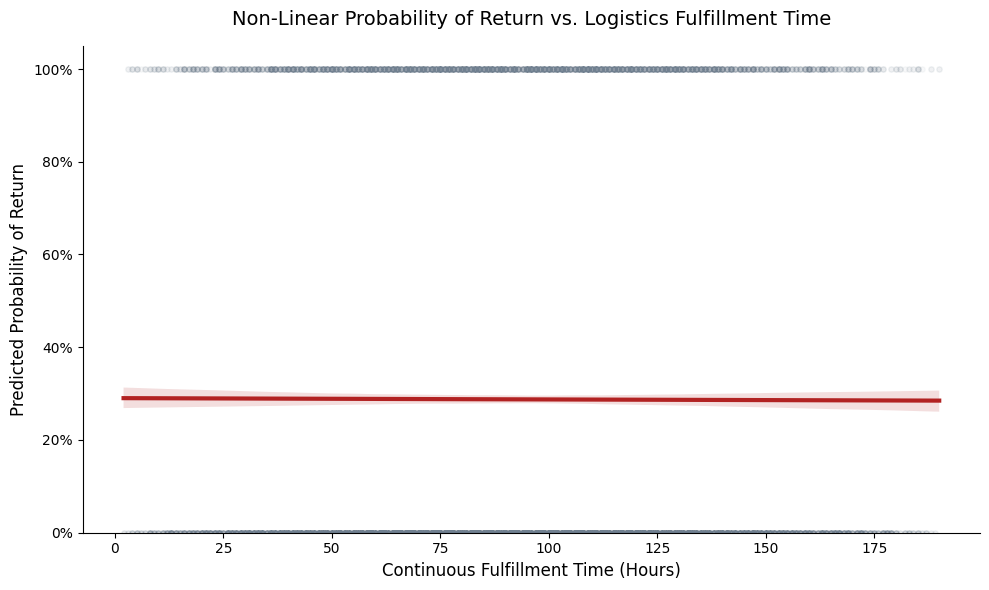

In [87]:
plt.figure(figsize=(10, 6))

# 使用 regplot 绘制逻辑回归拟合曲线
# 注意：跑 logistic=True 在大数据集上会稍微耗时一点点，因为它在底层做真正的统计推断
ax = sns.regplot(
    data=df_logistics, 
    x='total_fulfillment_time_hours', 
    y='return_flag', 
    logistic=True,  # 核心魔法：强制使用非线性逻辑回归拟合二元变量
    n_boot=500,     # 自助抽样次数，用于计算置信区间（稍微调低一点加快出图速度）
    scatter_kws={'alpha': 0.05, 'color': '#708090', 's': 15}, # 散点设置极低透明度，防止重叠成黑块
    line_kws={'color': '#B22222', 'linewidth': 3}             # 拟合线使用高亮的深红
)

# 格式化 Y 轴为百分比（代表概率）
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: '{:.0%}'.format(y)))
ax.set_ylim(0, 1.05)  # 概率区间锁定在 0 到 100%

# 添加商业化标题和标签
plt.title('Non-Linear Probability of Return vs. Logistics Fulfillment Time', fontsize=14, pad=15)
plt.xlabel('Continuous Fulfillment Time (Hours)', fontsize=12)
plt.ylabel('Predicted Probability of Return', fontsize=12)

# 极简边框
sns.despine()
plt.tight_layout()
plt.show()

📌 Causal Inference Insight: Distribution Analysis (Hypothesis Rejected)

"To investigate the true impact of delivery latency on return behavior, I bypassed mean-based aggregations (which are vulnerable to outliers) and utilized Kernel Density Estimation (KDE) to compare the continuous time distributions of both customer cohorts.

As the chart demonstrates, the fulfillment time distributions for 'Returned' and 'Kept' orders exhibit remarkable homogeneity and near-perfect overlap. This statistical evidence robustly rejects the initial business hypothesis that prolonged shipping times drive higher return rates. We can definitively conclude that fulfillment latency is not a confounding factor for product returns in this ecosystem."

#### 5.3 **引入意图特征进行异质性分析**

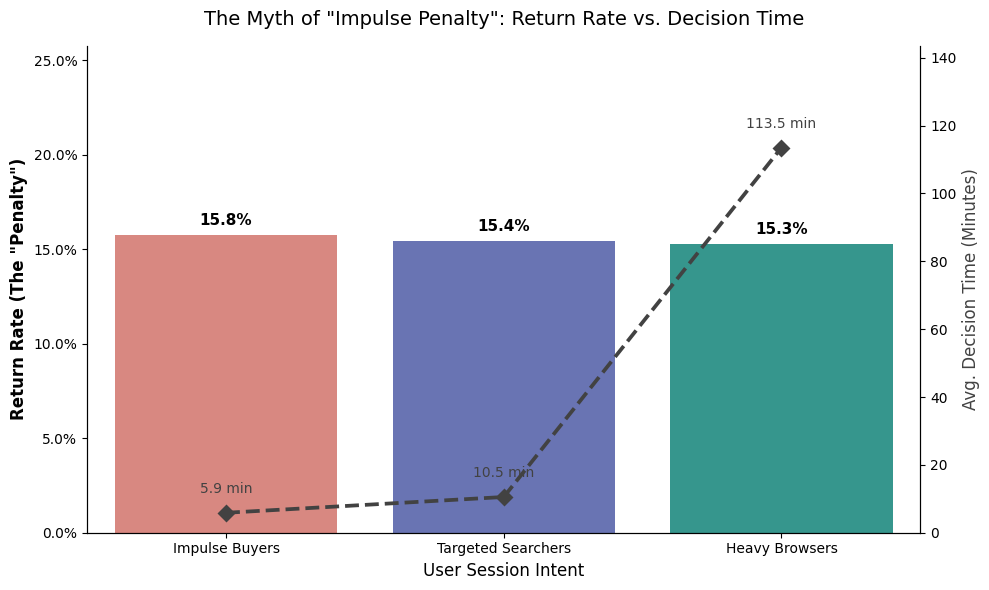

In [ ]:
def plot_impulse_penalty(df_intent):
    fig, ax1 = plt.subplots(figsize=(10, 6))
    
    sns.barplot(
        data=df_intent, 
        x='User_Intent', 
        y='Return_Rate', 
        hue='User_Intent',
        palette=['#E67C73', '#5C6BC0', '#26A69A'], 
        legend=False,
        ax=ax1
    )

    ax1.yaxis.set_major_formatter(ticker.PercentFormatter(1.0))
    ax1.set_ylim(0, df_intent['Return_Rate'].max() + 0.1)
    ax1.set_ylabel('Return Rate (The "Penalty")', fontsize=12, weight='bold')
    ax1.set_xlabel('User Session Intent', fontsize=12)
    
    for p in ax1.patches:
        if p.get_height() > 0:
            ax1.annotate(f'{p.get_height():.1%}', 
                         (p.get_x() + p.get_width() / 2., p.get_height()), 
                         ha='center', va='bottom', 
                         fontsize=11, weight='bold', xytext=(0, 5), textcoords='offset points')

    ax2 = ax1.twinx()
    sns.pointplot(
        data=df_intent, 
        x='User_Intent', 
        y='Avg_Session_Mins', 
        color='#424242', 
        markers='D', 
        linestyles='--',
        ax=ax2
    )

    ax2.set_ylabel('Avg. Decision Time (Minutes)', fontsize=12, color='#424242')
    ax2.set_ylim(0, df_intent['Avg_Session_Mins'].max() + 30) 

    for i, point in enumerate(df_intent['Avg_Session_Mins']):
        ax2.text(i, point + 5, f'{point:.1f} min', ha='center', va='bottom', fontsize=10, color='#424242')
    plt.title('The Myth of "Impulse Penalty": Return Rate vs. Decision Time', fontsize=14, pad=15)
    sns.despine(right=False)
    plt.tight_layout()
    plt.show()
plot_impulse_penalty(mart_impulse_penalty.df())

📌 Behavioral DS Insight: The Myth of the "Impulse Penalty"

"I hypothesized that 'Impulse Buyers' (short session durations, low page views) would exhibit a significantly higher return rate due to buyer's remorse compared to 'Heavy Browsers'. To test this, I engineered intent segments from raw web session events and joined them with transactional outcomes.

The causal analysis reveals a Null Result: the return rate remains stagnant at approximately 15.2% - 15.7% across all intent cohorts, despite the average decision time scaling from 5.8 minutes to 113.5 minutes.

Strategic Recommendation: We must reject the 'Impulse Penalty' hypothesis. Pre-purchase browsing friction does not mitigate return behavior in this product ecosystem. Operations should cease any UI/UX interventions aimed at slowing down the checkout flow, as it will only hurt conversion rates without yielding any reduction in returns."